# Feature selection for weekly Δstocks
Runs both pipelines on the **complete** and **full** datasets. Models, CV and config live in `common.py`.

- **MAE**: lower is better. **DA**: directional accuracy (build vs draw), higher is better.
- `k` is picked on walk-forward CV only; `test_*` is the untouched last 20%.

In [1]:
import os, common
print("Notebook runs in:", os.getcwd())
print("Python files here:", sorted(f for f in os.listdir() if f.endswith(".py")))
print("common.py loaded from:", common.__file__)

Notebook runs in: c:\Users\AL-OFQ\Documents\Lectures\Samsung Innovation campus\Data Pipeline\Feature_selection
Python files here: ['common.py', 'fs_mrmr_relieff.py', 'fs_pca.py']
common.py loaded from: c:\Users\AL-OFQ\Documents\Lectures\Samsung Innovation campus\Data Pipeline\Feature_selection\common.py


In [2]:
import json, pandas as pd
from common import FILES
import fs_mrmr_relieff as p1, fs_pca as p2

K_STEP = 1 #  3 for a quick run , 1- takes all the features

In [4]:
for t, p in FILES.items():
    print(t, "->", list(pd.read_csv(p, nrows=0).columns)[:3])

complete -> ['date', 'crude_stocks_ex_spr', 'crude_production']
full -> ['crude_stocks_ex_spr', 'crude_production', 'crude_imports']


[implied_lags] train (1282, 20) | test (321, 20)


ReliefF | SARIMAX: 100%|██████████| 20/20 [00:50<00:00,  2.50s/it]
ReliefF | LightGBM: 100%|██████████| 20/20 [00:53<00:00,  2.65s/it]
ReliefF | LSTM:   0%|          | 0/20 [00:00<?, ?it/s]

ReliefF | LSTM: 100%|██████████| 20/20 [07:50<00:00, 23.53s/it]
mRMR | SARIMAX: 100%|██████████| 20/20 [01:01<00:00,  3.05s/it]
mRMR | LightGBM: 100%|██████████| 20/20 [00:26<00:00,  1.34s/it]
mRMR | LSTM: 100%|██████████| 20/20 [08:36<00:00, 25.82s/it]


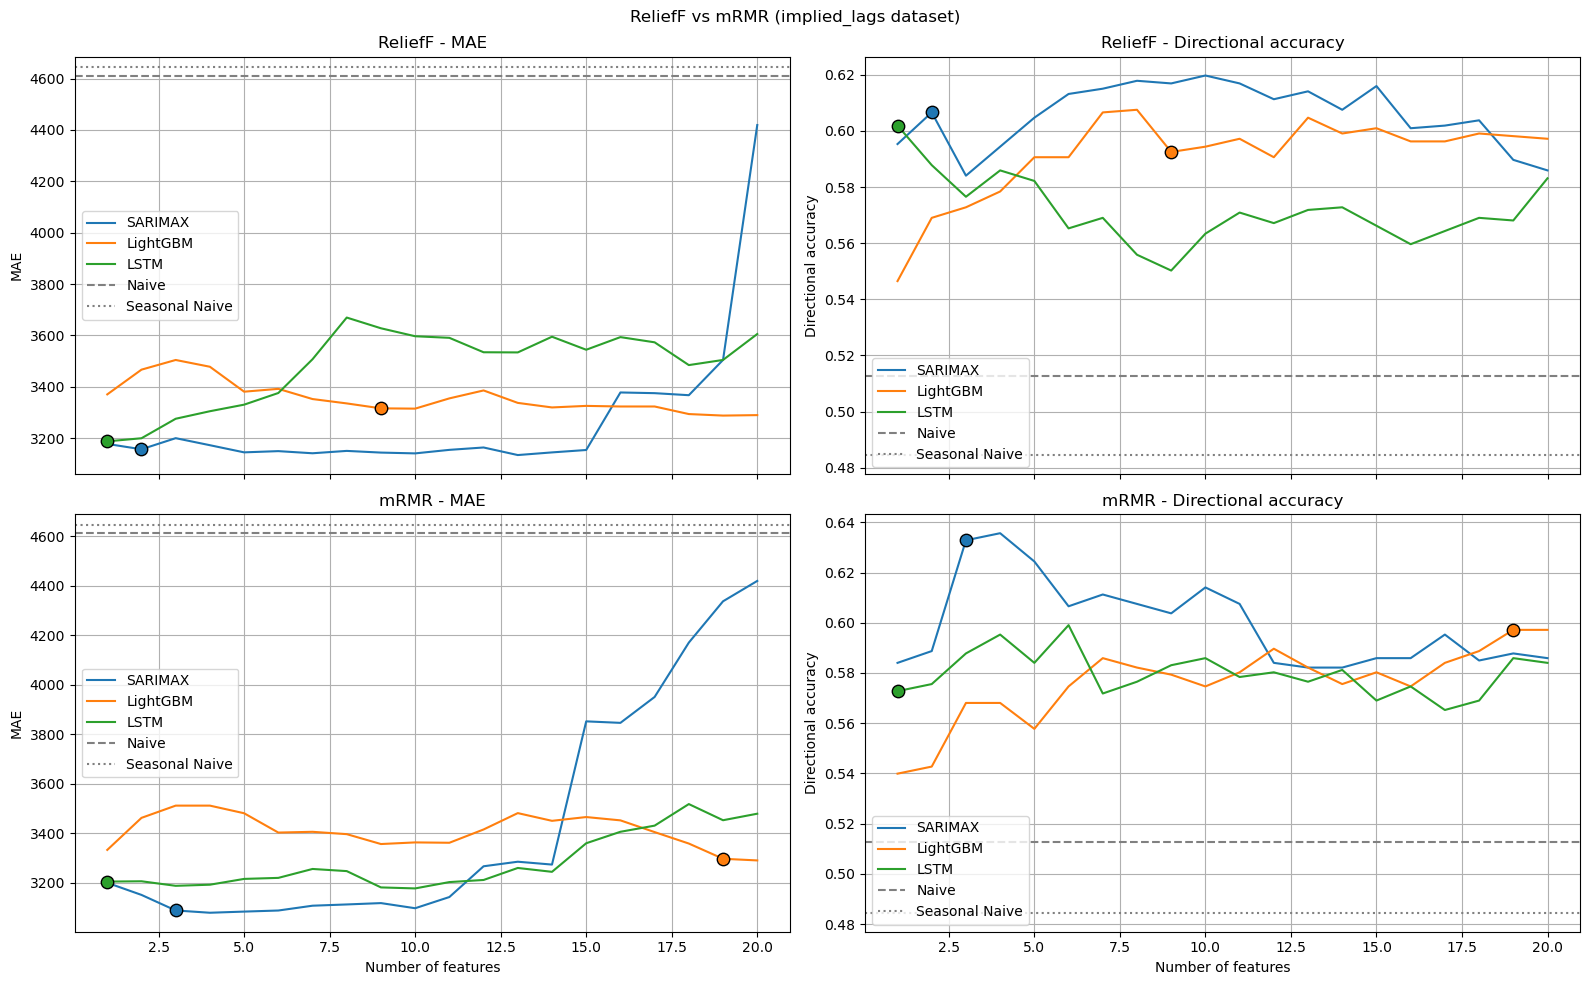

[implied_lags] train (1282, 20) | components for 95% variance: 14


PCA | SARIMAX: 100%|██████████| 20/20 [00:36<00:00,  1.83s/it]
PCA | LightGBM: 100%|██████████| 20/20 [01:24<00:00,  4.23s/it]
PCA | LSTM: 100%|██████████| 20/20 [09:39<00:00, 28.96s/it]


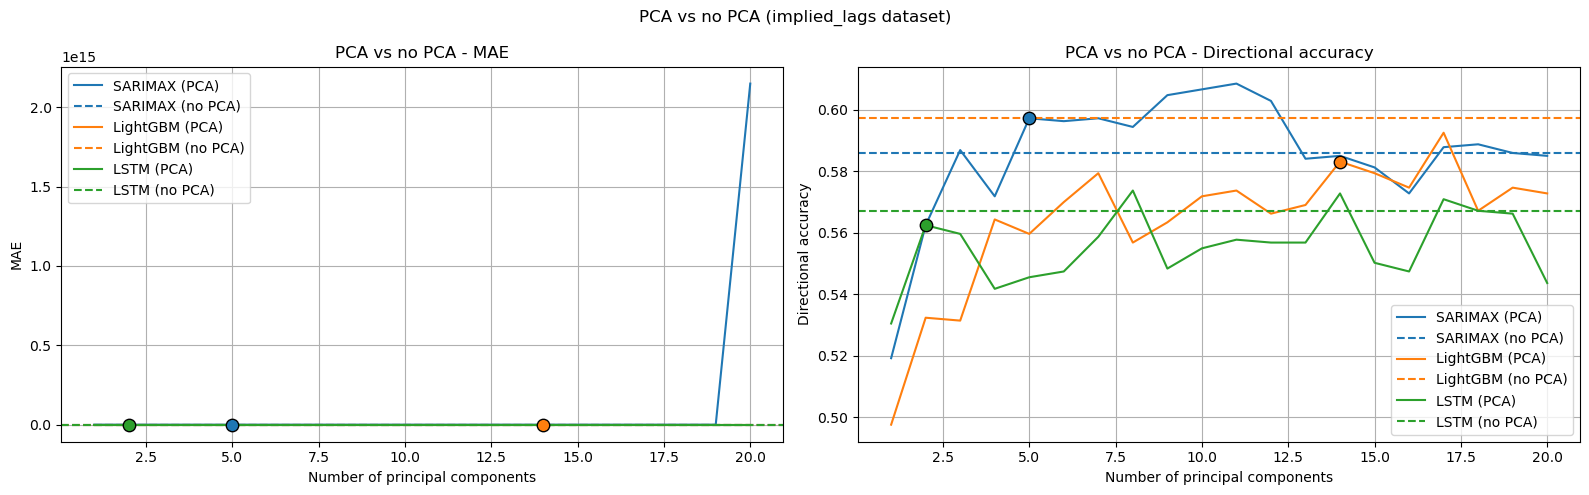

,method,model,k,cv_MAE,cv_DA,test_MAE,test_DA
0,ReliefF,SARIMAX,2,3156.2140,0.6066,4125.6742,0.6168
1,ReliefF,LightGBM,9,3315.6423,0.5925,4296.1676,0.6199
2,ReliefF,LSTM,1,3187.1179,0.6019,4126.8538,0.5981
3,mRMR,SARIMAX,3,3087.3455,0.6329,3923.9572,0.6480
4,mRMR,LightGBM,19,3296.3002,0.5972,4445.0101,0.5607
5,mRMR,LSTM,1,3204.1198,0.5728,4060.2419,0.6231
6,baseline,Naive,0,4612.1108,0.5127,6148.6636,0.5047
7,baseline,Seasonal Naive,0,4645.3362,0.4845,5975.9439,0.5234


,method,model,k,cv_MAE,cv_DA,test_MAE,test_DA,expl_var
0,baseline,Naive,0,4612.1108,0.5127,6148.6636,0.5047,NaN
1,baseline,Seasonal Naive,0,4645.3362,0.4845,5975.9439,0.5234,NaN
2,no PCA,SARIMAX,20,4419.2008,0.5859,4057.2877,0.6511,1.0000
3,PCA,SARIMAX,5,3177.2076,0.5972,3855.4747,0.6511,0.6347
4,no PCA,LightGBM,20,3288.8255,0.5972,4381.7225,0.5857,1.0000
5,PCA,LightGBM,14,3337.2934,0.5831,4502.7757,0.6199,0.9556
6,no PCA,LSTM,20,3359.5042,0.5671,4293.4167,0.6012,1.0000
7,PCA,LSTM,2,3272.5243,0.5624,4077.7813,0.6012,0.3808


,ReliefF | SARIMAX,ReliefF | LightGBM,ReliefF | LSTM,mRMR | SARIMAX,mRMR | LightGBM,mRMR | LSTM
0,refinery_utilisation,refinery_utilisation,refinery_utilisation,stocks_change_4wk_avg,stocks_change_4wk_avg,stocks_change_4wk_avg
1,gasoline_stocks,gasoline_stocks,NaN,gasoline_stocks,gasoline_stocks,NaN
2,NaN,stocks_vs_5yr_avg,NaN,refinery_utilisation,refinery_utilisation,NaN
3,NaN,stocks_change_4wk_avg,NaN,NaN,stocks_change_outlier,NaN
4,NaN,week_cos,NaN,NaN,implied_change,NaN
5,NaN,distillate_stocks,NaN,NaN,week_cos,NaN
6,NaN,week_sin,NaN,NaN,week_sin,NaN
7,NaN,brent_wti_spread,NaN,NaN,stocks_change,NaN
8,NaN,crude_imports,NaN,NaN,implied_change_lag1,NaN
9,NaN,NaN,NaN,NaN,crude_imports,NaN


In [6]:
# Rerun both pipelines on the new file (with implied_change lags)
from common import DATE
src = r"processed\crude_weekly_full_with_implied_lags.csv"
path = src.replace(".csv", "_no_cushing.csv")
pd.read_csv(src).drop(columns="cushing_stocks", errors="ignore").rename(columns={"date": DATE}).to_csv(path, index=False)

fs_new = p1.run("implied_lags", path, K_STEP)
pc_new = p2.run("implied_lags", path, K_STEP)
display(fs_new.round(4), pc_new.round(4))
display(pd.DataFrame({f"{m} | {k}": pd.Series(v) for m, d in json.load(open("results/fs_features_implied_lags.json"))["selected"].items() for k, v in d.items()}))

## 1. ReliefF & mRMR

[complete] train (936, 20) | test (235, 20)


ReliefF | SARIMAX: 100%|██████████| 20/20 [00:31<00:00,  1.57s/it]
ReliefF | LightGBM: 100%|██████████| 20/20 [00:46<00:00,  2.34s/it]
ReliefF | LSTM:   0%|          | 0/20 [00:00<?, ?it/s]

ReliefF | LSTM: 100%|██████████| 20/20 [07:18<00:00, 21.95s/it]
mRMR | SARIMAX: 100%|██████████| 20/20 [00:44<00:00,  2.21s/it]
mRMR | LightGBM: 100%|██████████| 20/20 [00:44<00:00,  2.24s/it]
mRMR | LSTM: 100%|██████████| 20/20 [08:21<00:00, 25.10s/it]


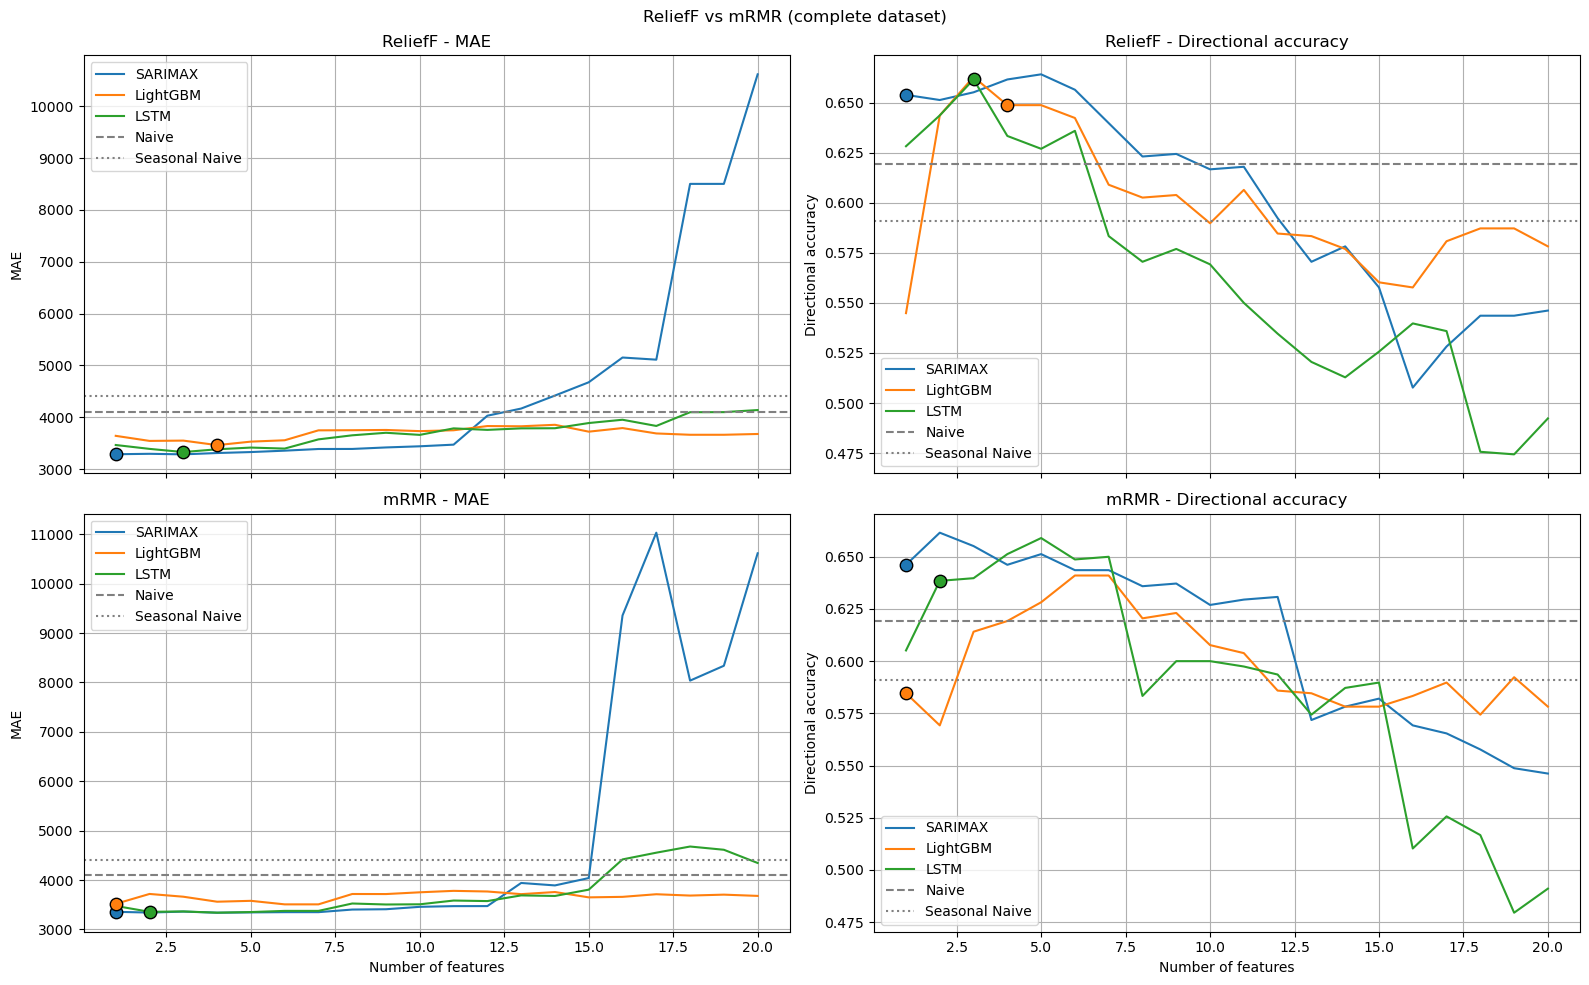

[full] train (1282, 19) | test (321, 19)


ReliefF | SARIMAX: 100%|██████████| 19/19 [00:41<00:00,  2.20s/it]
ReliefF | LightGBM: 100%|██████████| 19/19 [00:43<00:00,  2.27s/it]
ReliefF | LSTM: 100%|██████████| 19/19 [08:52<00:00, 28.04s/it]
mRMR | SARIMAX: 100%|██████████| 19/19 [00:32<00:00,  1.73s/it]
mRMR | LightGBM: 100%|██████████| 19/19 [00:14<00:00,  1.34it/s]
mRMR | LSTM: 100%|██████████| 19/19 [05:52<00:00, 18.56s/it]


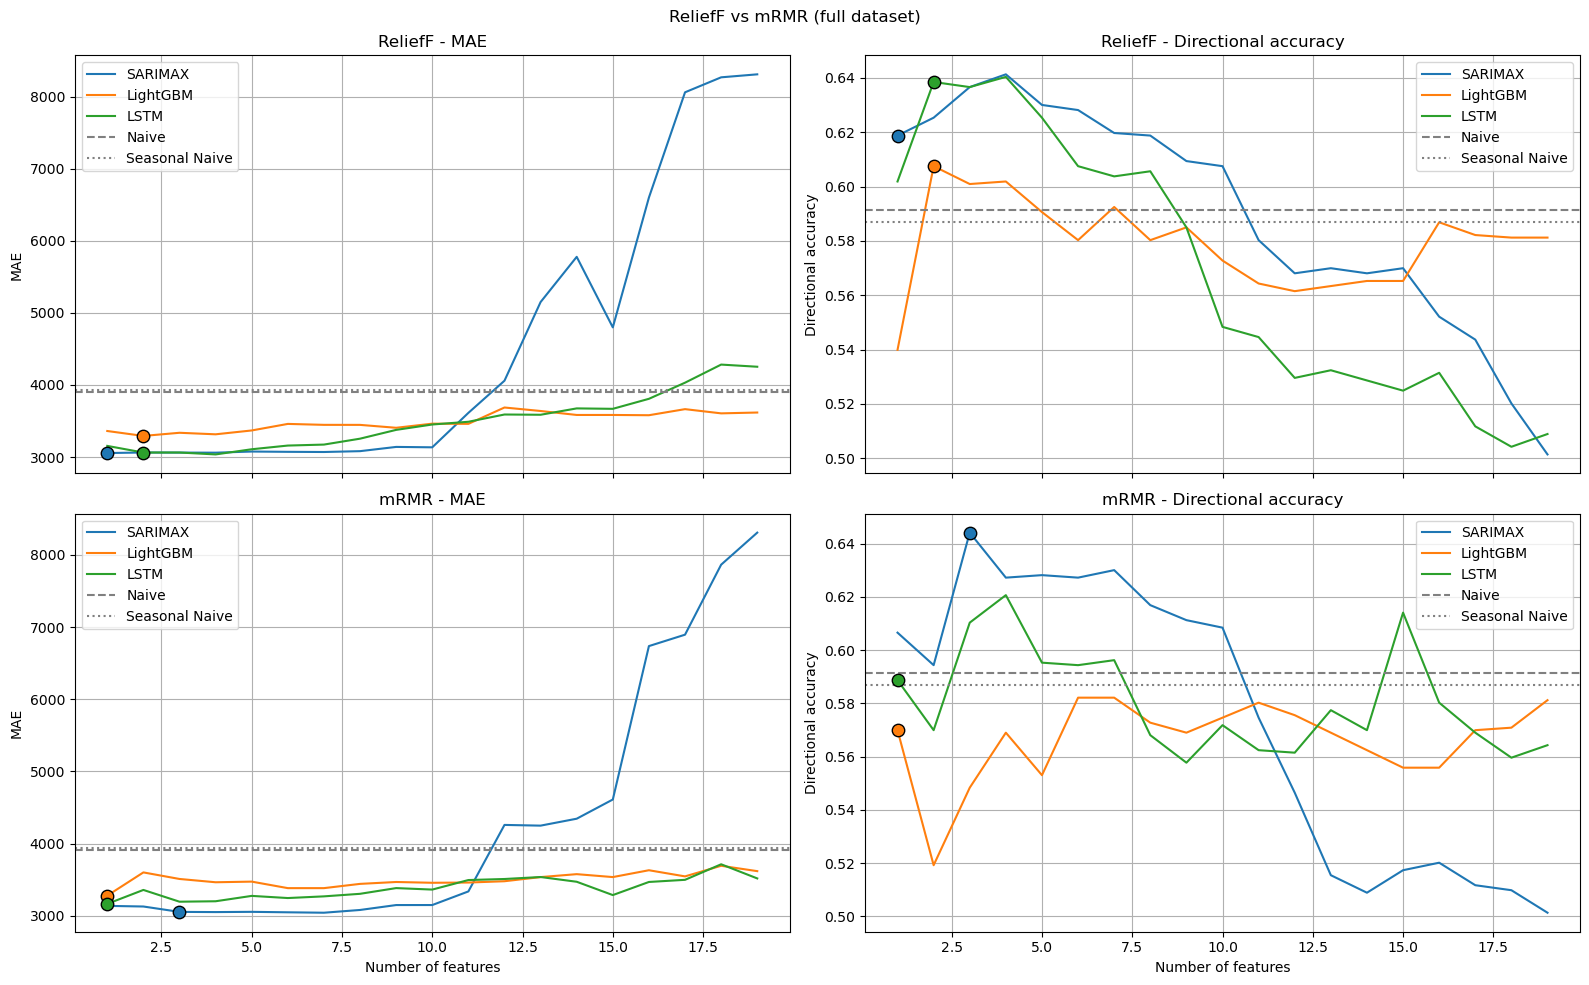

method           model  k     cv_MAE   cv_DA   test_MAE  test_DA
file                                                                          
complete 0   ReliefF         SARIMAX  1  3288.0552  0.6538  4012.8403   0.5702
         1   ReliefF        LightGBM  4  3463.8477  0.6487  4338.4493   0.6128
         2   ReliefF            LSTM  3  3329.9983  0.6615  3962.5649   0.6468
         3      mRMR         SARIMAX  1  3356.5694  0.6462  4106.4348   0.5489
         4      mRMR        LightGBM  1  3518.0939  0.5846  4380.9596   0.5106
         5      mRMR            LSTM  2  3356.4389  0.6385  3921.7135   0.6128
         6  baseline           Naive  0  4099.2103  0.6192  5556.5660   0.5447
         7  baseline  Seasonal Naive  0  4404.3731  0.5910  5464.5277   0.5447
full     0   ReliefF         SARIMAX  1  3054.7969  0.6188  3951.4356   0.5670
         1   ReliefF        LightGBM  2  3292.3213  0.6075  4249.4293   0.6012
         2   ReliefF            LSTM  2  3061.9745  0.6385  3863.4397   0.6262
         3      mRMR         SARIMAX  3  3052.4721  0.6441  4080.3489   0.5670
         4      mRMR        LightGBM  1  3277.8739  0.5700  4173.8356   0.5701
         5      mRMR            LSTM  1  3163.5587  0.5887  4073.1128   0.5452
         6  baseline           Naive  0  3905.4178  0.5915  5312.9034   0.5607
         7  baseline  Seasonal Naive  0  3936.0075  0.5869  5684.0312   0.5483

In [ ]:
fs = pd.concat({t: p1.run(t, p, K_STEP) for t, p in FILES.items()}, names=['file'])
fs.round(4)

## 2. PCA vs no PCA

[complete] train (936, 20) | components for 95% variance: 12


PCA | SARIMAX: 100%|██████████| 20/20 [00:26<00:00,  1.30s/it]
PCA | LightGBM: 100%|██████████| 20/20 [00:07<00:00,  2.62it/s]
PCA | LSTM: 100%|██████████| 20/20 [06:29<00:00, 19.46s/it]


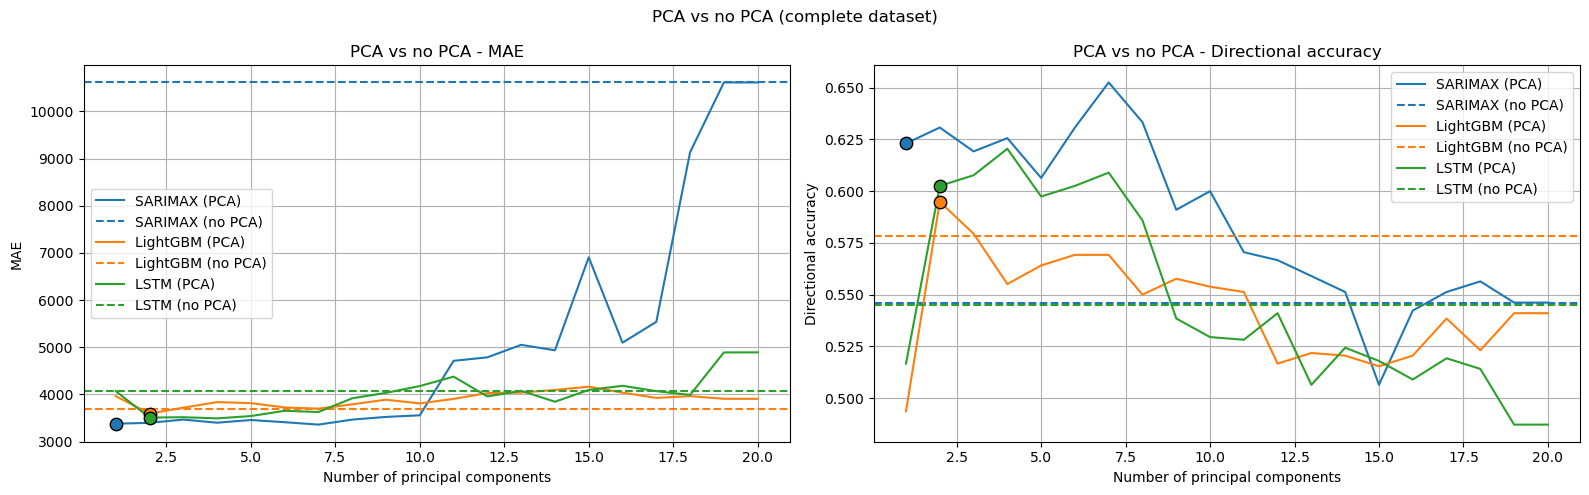

[full] train (1282, 19) | components for 95% variance: 13


PCA | SARIMAX: 100%|██████████| 19/19 [00:26<00:00,  1.42s/it]
PCA | LightGBM: 100%|██████████| 19/19 [00:10<00:00,  1.81it/s]
PCA | LSTM: 100%|██████████| 19/19 [09:33<00:00, 30.17s/it]


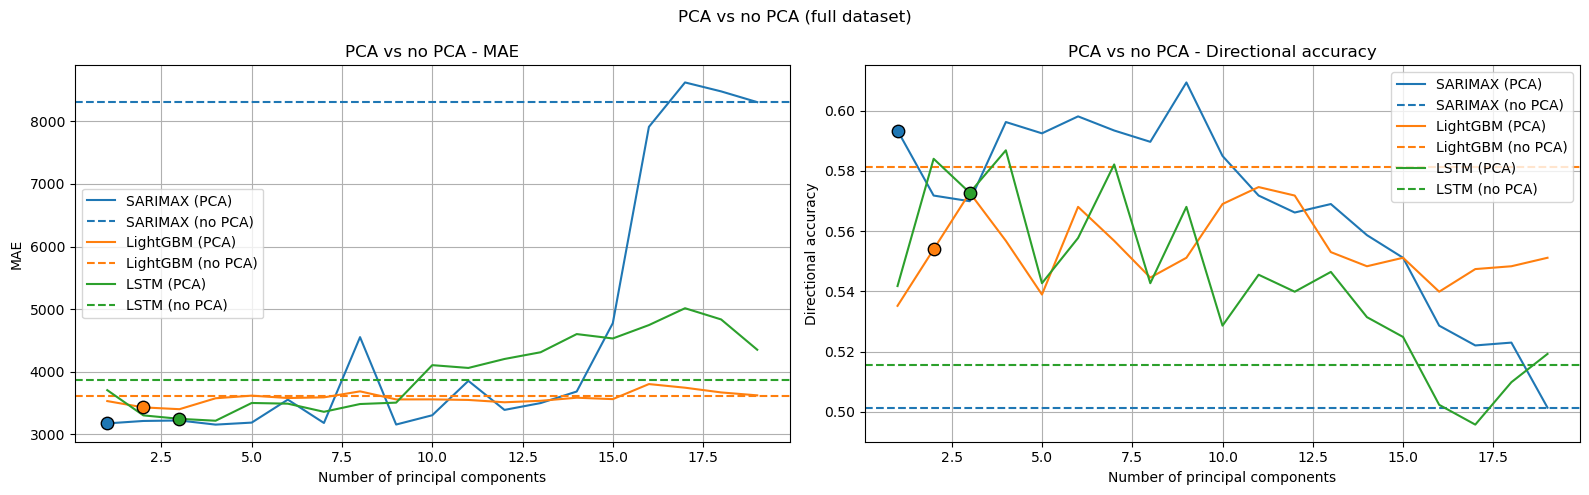

method           model   k      cv_MAE   cv_DA   test_MAE  \
file                                                                      
complete 0  baseline           Naive   0   4099.2103  0.6192  5556.5660   
         1  baseline  Seasonal Naive   0   4404.3731  0.5910  5464.5277   
         2    no PCA         SARIMAX  20  10615.2640  0.5462  4533.8410   
         3       PCA         SARIMAX   1   3377.0043  0.6231  4144.0823   
         4    no PCA        LightGBM  20   3678.7638  0.5782  4487.5512   
         5       PCA        LightGBM   2   3591.9973  0.5949  4636.1033   
         6    no PCA            LSTM  20   4062.5873  0.5449  4887.7387   
         7       PCA            LSTM   2   3507.7969  0.6026  4495.3082   
full     0  baseline           Naive   0   3905.4178  0.5915  5312.9034   
         1  baseline  Seasonal Naive   0   3936.0075  0.5869  5684.0312   
         2    no PCA         SARIMAX  19   8308.3182  0.5014  4587.2972   
         3       PCA         SARIMAX   1   3173.2283  0.5934  4066.5396   
         4    no PCA        LightGBM  19   3614.4381  0.5812  4927.0211   
         5       PCA        LightGBM   2   3429.1013  0.5540  4305.0846   
         6    no PCA            LSTM  19   3863.7369  0.5155  5721.3262   
         7       PCA            LSTM   3   3246.2731  0.5728  4153.9019   

            test_DA  expl_var  
file                           
complete 0   0.5447       NaN  
         1   0.5447       NaN  
         2   0.5532    1.0000  
         3   0.5404    0.2683  
         4   0.6298    1.0000  
         5   0.5489    0.4228  
         6   0.5277    1.0000  
         7   0.5787    0.4228  
full     0   0.5607       NaN  
         1   0.5483       NaN  
         2   0.5452    1.0000  
         3   0.5358    0.2442  
         4   0.5514    1.0000  
         5   0.5483    0.3947  
         6   0.4829    1.0000  
         7   0.5639    0.5183

In [ ]:
pc = pd.concat({t: p2.run(t, p, K_STEP) for t, p in FILES.items()}, names=['file'])
pc.round(4)

## 3. Best setup per model (chosen by CV MAE)

In [ ]:
allres = pd.concat([fs, pc]).reset_index(level=0).drop_duplicates(['file', 'method', 'model'])
allres.sort_values('cv_MAE').groupby(['file', 'model']).head(1).sort_values(['file', 'cv_MAE']).round(4)

,file,method,model,k,cv_MAE,cv_DA,test_MAE,test_DA,expl_var
0,complete,ReliefF,SARIMAX,1,3288.0552,0.6538,4012.8403,0.5702,NaN
2,complete,ReliefF,LSTM,3,3329.9983,0.6615,3962.5649,0.6468,NaN
1,complete,ReliefF,LightGBM,4,3463.8477,0.6487,4338.4493,0.6128,NaN
6,complete,baseline,Naive,0,4099.2103,0.6192,5556.5660,0.5447,NaN
7,complete,baseline,Seasonal Naive,0,4404.3731,0.5910,5464.5277,0.5447,NaN
3,full,mRMR,SARIMAX,3,3052.4721,0.6441,4080.3489,0.5670,NaN
2,full,ReliefF,LSTM,2,3061.9745,0.6385,3863.4397,0.6262,NaN
4,full,mRMR,LightGBM,1,3277.8739,0.5700,4173.8356,0.5701,NaN
6,full,baseline,Naive,0,3905.4178,0.5915,5312.9034,0.5607,NaN
7,full,baseline,Seasonal Naive,0,3936.0075,0.5869,5684.0312,0.5483,NaN


## 4. Selected features

In [ ]:
for t in FILES:
    sel = json.load(open(f'results/fs_features_{t}.json'))['selected']
    print(t); display(pd.DataFrame({f'{meth} | {m}': pd.Series(c) for meth, d in sel.items() for m, c in d.items()}))

complete


,ReliefF | SARIMAX,ReliefF | LightGBM,ReliefF | LSTM,mRMR | SARIMAX,mRMR | LightGBM,mRMR | LSTM
0,refinery_utilisation,refinery_utilisation,refinery_utilisation,stocks_change_4wk_avg,stocks_change_4wk_avg,stocks_change_4wk_avg
1,NaN,week_sin,week_sin,NaN,NaN,refinery_utilisation
2,NaN,week_cos,week_cos,NaN,NaN,NaN
3,NaN,stocks_change_4wk_avg,NaN,NaN,NaN,NaN


full


,ReliefF | SARIMAX,ReliefF | LightGBM,ReliefF | LSTM,mRMR | SARIMAX,mRMR | LightGBM,mRMR | LSTM
0,refinery_utilisation,refinery_utilisation,refinery_utilisation,stocks_change_4wk_avg,stocks_change_4wk_avg,stocks_change_4wk_avg
1,NaN,week_sin,week_sin,crude_imports,NaN,NaN
2,NaN,NaN,NaN,refinery_utilisation,NaN,NaN


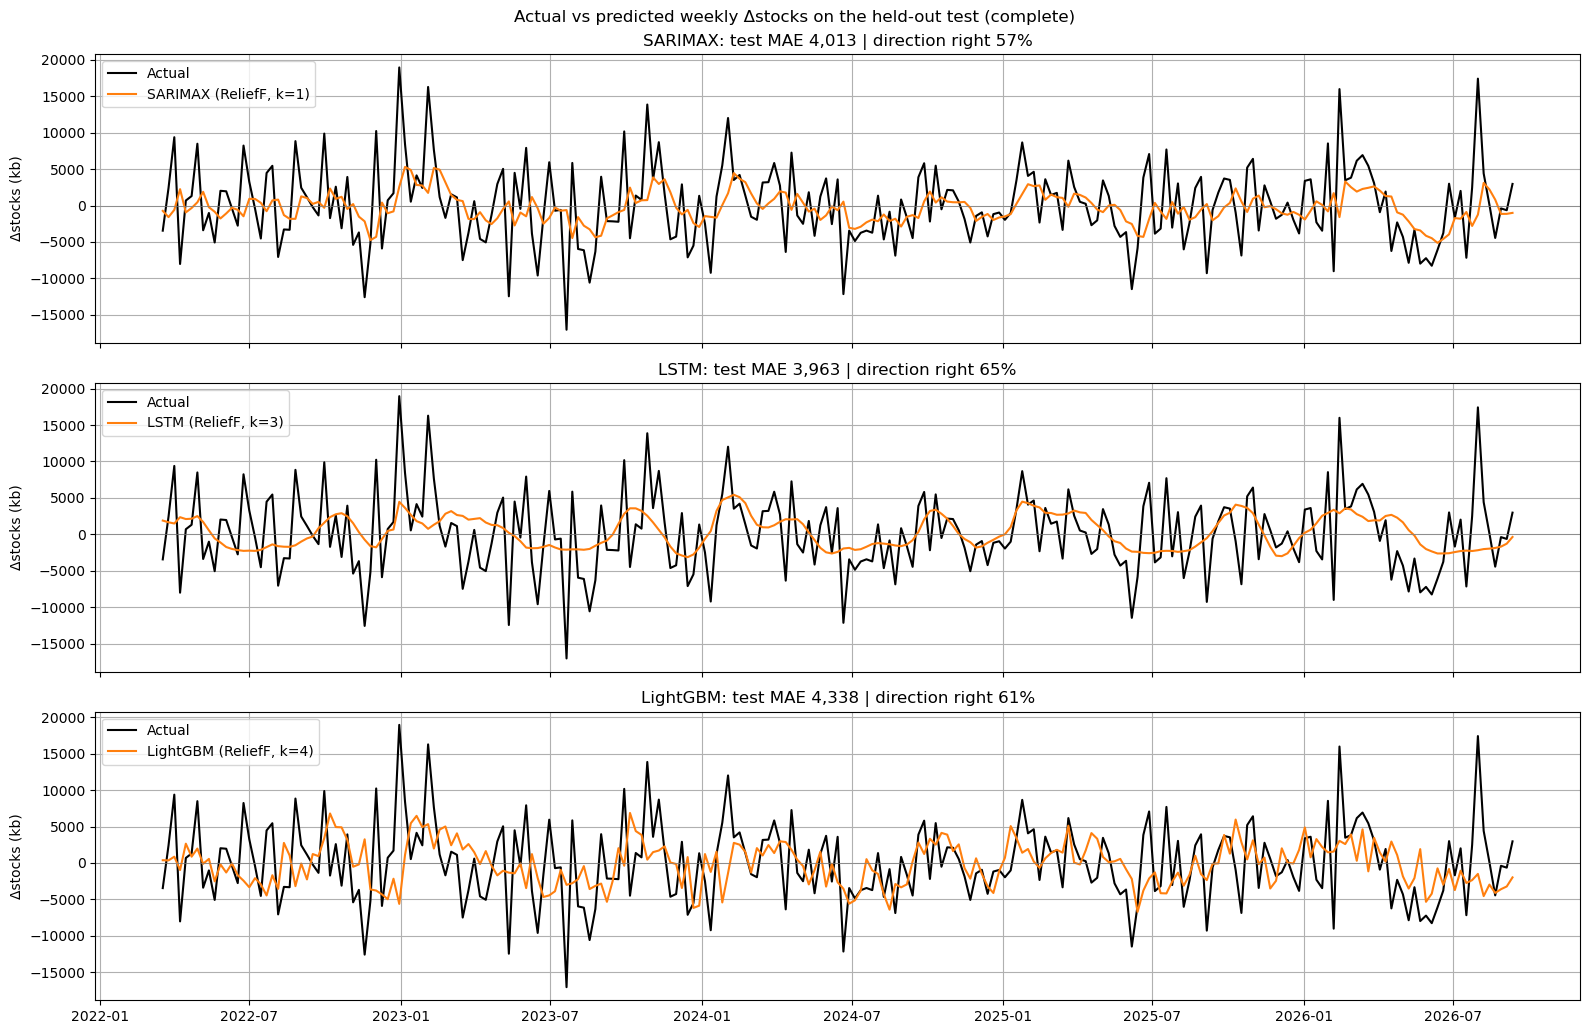

In [ ]:
# Actual vs predicted on the held-out test, best setup per model (chosen by CV)
from common import load, score, MODELS
import matplotlib.pyplot as plt

tag = "complete"   # or "full"
Xtr, ytr, Xte, yte = load(FILES[tag])
sel = json.load(open(f"results/fs_features_{tag}.json"))["selected"]
best = fs.loc[tag].query("method != 'baseline'").sort_values("cv_MAE").drop_duplicates("model")

fig, axes = plt.subplots(len(best), 1, figsize=(16, 3.5 * len(best)), sharex=True)
for ax, (_, r) in zip(axes, best.iterrows()):
    cols = sel[r.method][r.model]
    pred = MODELS[r.model](Xtr[cols].values, ytr, Xte[cols].values, yte)
    mae, da = score(yte, pred)
    ax.plot(Xte.index, yte, color="black", lw=1.5, label="Actual")
    ax.plot(Xte.index, pred, color="tab:orange", label=f"{r.model} ({r.method}, k={r.k})")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set(title=f"{r.model}: test MAE {mae:,.0f} | direction right {da:.0%}", ylabel="Δstocks (kb)")
    ax.grid(True); ax.legend(loc="upper left")
fig.suptitle(f"Actual vs predicted weekly Δstocks on the held-out test ({tag})"); plt.tight_layout()
plt.savefig(f"results/predictions_{tag}.png", dpi=250, bbox_inches="tight"); plt.show()

In [ ]:
f = d[d.stocks_change_outlier == 1]
print(len(f), "spike weeks | correlation with next week:", round(f.stocks_change.corr(f.target_next_week_change), 2))

5 spike weeks | correlation with next week: 0.73


In [ ]:
import numpy as np
from common import naive

spike = np.abs(yte) > np.quantile(np.abs(ytr), 0.9)   # biggest 10% of weekly moves (threshold from training data only) 
preds = {"Naive": naive(None, ytr, None, yte)}
for _, r in best.iterrows():
    cols = sel[r.method][r.model]
    preds[r.model] = MODELS[r.model](Xtr[cols].values, ytr, Xte[cols].values, yte)

err = pd.DataFrame({m: {f"normal weeks (n={(~spike).sum()})": np.abs(yte - p)[~spike].mean(),
                        f"spike weeks (n={spike.sum()})": np.abs(yte - p)[spike].mean(),
                        "all weeks": np.abs(yte - p).mean()} for m, p in preds.items()})
err.round(0)

,Naive,SARIMAX,LSTM,LightGBM
normal weeks (n=198),4618.0,2942.0,2937.0,3323.0
spike weeks (n=37),10582.0,9742.0,9452.0,9770.0
all weeks,5557.0,4013.0,3963.0,4338.0


In normal weeks, the models reduce forecast error by about a third compared with the Naive baseline. In the 37 weeks with the largest moves, all models, including Naive, miss by 9–11 million barrels, and these 16% of weeks account for about 38% of total error

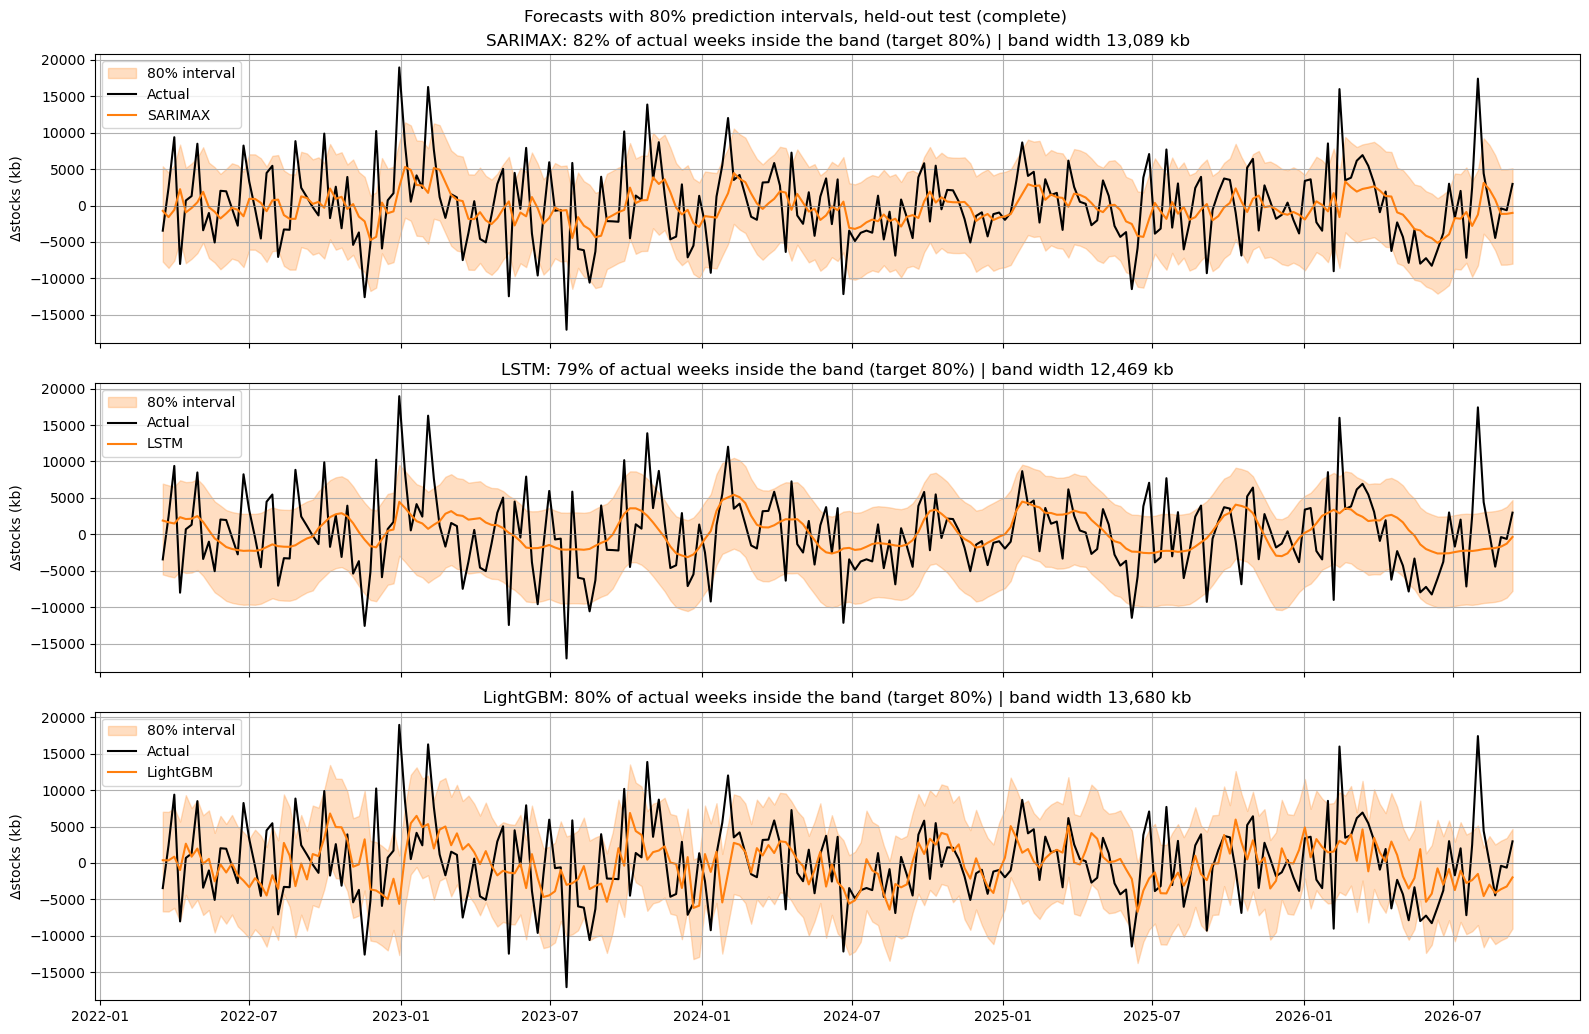

In [ ]:
# 80% prediction intervals: forecast + the 10th and 90th percentile of the model's past errors
c = int(len(ytr) * 0.8)   # last 20% of the training years = calibration period
fig, axes = plt.subplots(len(best), 1, figsize=(16, 3.5 * len(best)), sharex=True)
for ax, (_, r) in zip(axes, best.iterrows()):
    Xa = Xtr[sel[r.method][r.model]].values
    cal = MODELS[r.model](Xa[:c], ytr[:c], Xa[c:], ytr[c:])      # errors on training weeks the model hasn't seen
    lo, hi = np.quantile(ytr[c:] - cal, [0.1, 0.9])
    pred = preds[r.model]
    inside = np.mean((yte >= pred + lo) & (yte <= pred + hi))
    ax.fill_between(Xte.index, pred + lo, pred + hi, color="tab:orange", alpha=0.25, label="80% interval")
    ax.plot(Xte.index, yte, color="black", lw=1.5, label="Actual")
    ax.plot(Xte.index, pred, color="tab:orange", label=r.model)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set(title=f"{r.model}: {inside:.0%} of actual weeks inside the band (target 80%) | band width {hi - lo:,.0f} kb", ylabel="Δstocks (kb)")
    ax.grid(True); ax.legend(loc="upper left")
fig.suptitle(f"Forecasts with 80% prediction intervals, held-out test ({tag})"); plt.tight_layout()
plt.savefig(f"results/intervals_{tag}.png", dpi=250, bbox_inches="tight"); plt.show()

## 5. Data validation
Before trusting the results, we check the input files for the most common time-series mistakes:

- **Target alignment:** `target_next_week_change` must equal next week's `stocks_change`, so each row predicts the future, not the present.
- **Look-ahead in features:** `stocks_change_4wk_avg` must use only the current and past weeks, never future ones.
- **Missing values:** rows with gaps are dropped before modelling, so we check how many rows each file loses and which column causes it.

In [ ]:
import numpy as np, pandas as pd
from common import FILES, DATE, TARGET

def same(a, b):
    m = a.notna() & b.notna()
    return np.allclose(a[m], b[m])

for tag, path in FILES.items():
    d = pd.read_csv(path, parse_dates=[DATE]).sort_values(DATE)
    print(f"{tag}: {len(d)} rows from {d[DATE].min().date()} -> after dropna {len(d.dropna())} rows from {d.dropna()[DATE].min().date()}")
    print("  columns with gaps:", d.isna().sum()[lambda s: s > 0].to_dict())
    print("  target = next week's change:", same(d[TARGET], d["stocks_change"].shift(-1)))
    print("  4wk avg uses only past weeks:", same(d["stocks_change_4wk_avg"], d["stocks_change"].rolling(4).mean()))

complete: 1171 rows from 2004-04-09 -> after dropna 1171 rows from 2004-04-09
  columns with gaps: {}
  target = next week's change: True
  4wk avg uses only past weeks: True
full: 1864 rows from 1991-01-04 -> after dropna 1171 rows from 2004-04-09
  columns with gaps: {'crude_exports': 5, 'cushing_stocks': 692, 'stocks_change': 1, 'target_next_week_change': 1, 'stocks_change_4wk_avg': 4, 'spr_change': 1, 'implied_change': 5, 'stocks_vs_5yr_avg': 260}
  target = next week's change: True
  4wk avg uses only past weeks: True


**Result:** Both leakage checks pass on both files. The `full` file drops from 1,864 rows (starting 1991) to the same 1,171 rows as `complete` (starting 2004), because `cushing_stocks` is missing for its first 692 weeks. That is why both files gave identical results.

**Reading the results:** keep the smallest feature set that clearly beats the Naive and Seasonal Naive lines. If PCA does not clearly beat *no PCA*, keep named features, since SHAP and the Scenario page need them.